### TO DO:

In [36]:
#TO DO - everything needed modifying is done here
#update to the semester if needed (check where the data is)
folder = "/Fall 2022/"

#TO DO: MODIFY T0 YOUR COUNTRY below -
#No need change elsewhere, unless stated otherwise
main_country = "Gambia"

#TO DO: MODIFY YOUR COMPARABLE COUNTRIES HERE - MD
#make sure to include your main country (you modified already above)
comparable_countries = [main_country, 'Sierra Leone', 'Senegal', 'Mali']

#emerging economies for SDV:
sdv_emerging_countries = ["China", "Singapore"]
#leading economies for SDV:
sdv_leading_countries = ['France, Monaco']

#SDV's list - any possible note name changes
sdv_comparable_countries = [main_country, 'Sierra Leone', 'Senegal', 'Mali']



#TO DO: Change to correct years


root_path = 'drive/My Drive/ECI Research/4. Code Files/2022 Fall - Code/Data/' #+ folder +'Data/'



begin_year = 2019
end_year = 2021


#### Import Packages

In [2]:
!pip install xlwt
from google.colab import files
import io
import os
from tqdm import tqdm
import csv

import statsmodels.api as sm
import statsmodels.formula.api as smf
import math
from sklearn.linear_model import LinearRegression

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
from scipy import linalg as LA
import operator
from xlwt import Workbook
import xlwt

import plotly.express as px

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import pickle

zzz=np.random.randint(1,100)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.0/100.0 kB 1.2 MB/s eta 0:00:00


Install the kaleido package for exporting images

In [ ]:
!pip install -U kaleido

#needed to downgrade plotly for kaleido to work; the code seems to run fine with the lower version,
#but let me know if we run into issues
!pip install plotly==5.3.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 MB 11.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
lida 0.0.10 requires fastapi, which is not installed.
lida 0.0.10 requires python-multipart, which is not installed.
lida 0.0.10 requires uvicorn, which is not installed.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.9/23.9 MB 27.8 MB/s eta 0:00:00
  Attempting uninstall: plotly
    Found existing installation: plotly 5.15.0
    Uninstalling plotly-5.15.0:
      Successfully uninstalled plotly-5.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
lida 0.0.10 requires fastapi, which is not installed.
lida 0.0.10 requires python-multipart, which is not installed.
lida 0.0.10 requires uvicorn, which is not in

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


# Import Data

In [37]:
import pandas as pd



dataframes = []
dataframes_cl = []

for year in range(begin_year, end_year+1):
    data_path = root_path + f'{begin_year}-{end_year} cleaned/{year}clean.csv'
    data_df = pd.read_csv(data_path)
    data_df_cl = pd.read_csv(data_path, index_col=0)
    dataframes.append(data_df)
    dataframes_cl.append(data_df_cl)

#To be consistent with current variable naming system
for df_entry in range(0,len(dataframes)):
  exec(f"df_{begin_year+df_entry} = dataframes[df_entry]")


df_begin = dataframes[0]
df_middle = dataframes[1]
df_end = dataframes[2]
df_begin_cl = dataframes_cl[0]
df_middle_cl = dataframes_cl[1]
df_end_cl = dataframes_cl[2]

gdp_path = root_path + 'GDP4.csv'
df7 = pd.read_csv(gdp_path)
df7_cl = df7.drop(columns=['Country Code', 'Series Name']).dropna()


In [8]:
#turns dataframe into matrix, cleans and checks data as well (nonzero values)
def df_to_matrix(dfa):
  raw_matrixa = dfa.to_numpy()
  matrixa = [list(dfa.columns)]

  for row in raw_matrixa:

    stripped=np.char.strip(np.array(row[1::]).astype(str),chars='_')
    if np.min(stripped.astype(float)) > 0:
      matrixa.append(list(row))

  return matrixa

In [9]:
## UPDATED - MD: needed to deal with non-numeric str and NAN for df7 (GDP4 file)
# equivalent to df_to_matrix(dfa)

def df7_to_matrix(df7_cl):
    temp = df7_cl.dropna()

    # Create an empty dictionary
    gdp_range_dict = {}

    # Iterate over the rows of the data frame
    for index, row in temp.iterrows():
      # Get the country name
      country = row['Country Name']
      year_value_list = []
      for year in range(begin_year, end_year+1):

        value_year = row[str(year)]
        if value_year.isnumeric():
          value_year = float(value_year)
        else:
          value_year = None
        year_value_list.append((year, value_year))
      gdp_range_dict[country] = year_value_list

    # Iterate over the rows of the data frame

    # The output dictionary should now have an entry for each country in the data frame
    return gdp_range_dict

In [10]:
#UPDATED
mxlist = []
for i in range(0, len(dataframes)):
  mxlist.append(df_to_matrix(dataframes[i]))

#to be consistent with naming
matrix = mxlist[0]
matrix2 = mxlist[1]
matrix3 = mxlist[2]

#matrix = df_to_matrix(df_2019) #for 2019
#matrix2 = df_to_matrix(df_middle) #for 2020
#matrix3 = df_to_matrix(df_end) #for 2021

## Clean matrix
# for GDP up to 2021 including
matrix7 = df7_to_matrix(df7) #for GDP up to 2021 including
gdp_range_dict = matrix7
#check gdp_19to21_dict (now gdp_range_dict) values
print(gdp_range_dict)

{'Afghanistan': [(2019, 18799450743.0), (2020, 20116137326.0), (2021, None)], 'Albania': [(2019, 15401830754.0), (2020, 15131866271.0), (2021, 18260043500.0)], 'Algeria': [(2019, 171767403748.0), (2020, 145009181491.0), (2021, 167983141738.0)], 'American Samoa': [(2019, 648000000.0), (2020, 709000000.0), (2021, None)], 'Andorra': [(2019, 3155149348.0), (2020, 2891001149.0), (2021, 3329910724.0)], 'Angola': [(2019, 69309104807.0), (2020, 53619071176.0), (2021, 72546985709.0)], 'Antigua and Barbuda': [(2019, 1687533333.0), (2020, 1370281481.0), (2021, 1471125926.0)], 'Argentina': [(2019, 452818426183.0), (2020, 389591035521.0), (2021, 491492700657.0)], 'Armenia': [(2019, 13619291361.0), (2020, 12641209802.0), (2021, 13861183874.0)], 'Aruba': [(2019, 3310055866.0), (2020, 2496648045.0), (2021, None)], 'Australia': [(2019, 1391952510370.0), (2020, 1327836171069.0), (2021, 1542659899993.0)], 'Austria': [(2019, 445011872704.0), (2020, 433258467677.0), (2021, 477082467454.0)], 'Azerbaijan': [

In [35]:
country_list = []
for i in range(1,len(matrix3)):
  country_list.append(matrix[i][0])
country_list

['Angola',
 'Argentina',
 'Armenia',
 'Aruba',
 'Australia',
 'Austria',
 'Azerbaijan',
 'Bahrain',
 'Barbados',
 'Belarus',
 'Belgium',
 'Belize',
 'Benin',
 'Bermuda',
 'Plurinational State of Bolivia',
 'Bosnia Herzegovina',
 'Botswana',
 'Brazil',
 'Brunei Darussalam',
 'Bulgaria',
 'Burundi',
 'Cambodia',
 'Canada',
 'Chile',
 'China',
 'China, Hong Kong Special Administrative Region',
 'Colombia',
 'Congo',
 'Croatia',
 'Cyprus',
 'Czechia',
 'Democratic Republic of the Congo',
 'Denmark',
 'Ecuador',
 'Egypt',
 'El Salvador',
 'Estonia',
 'Ethiopia',
 'EU-28',
 'Fiji',
 'Finland',
 'France, Monaco',
 'French Polynesia',
 'Georgia',
 'Germany',
 'Greece',
 'Grenada',
 'Guyana',
 'Hungary',
 'Iceland',
 'India',
 'Indonesia',
 'Ireland',
 'Israel',
 'Italy',
 'Jamaica',
 'Japan',
 'Jordan',
 'Kazakhstan',
 'Kenya',
 'Kuwait',
 'Kyrgyzstan',
 'Latvia',
 'Lebanon',
 'Lesotho',
 'Lithuania',
 'Luxembourg',
 'Madagascar',
 'Malawi',
 'Malaysia',
 'Mali',
 'Malta',
 'Mexico',
 'Mozambi

# ECI & PCI

MCP

In [11]:
#compute mcp
#input is matrix, output is the original product and country lists, the MCP values, the product sums, and the country sums

def compute_mcp(matrix):
  product_list = matrix[0][1::]
  country_list = []
  for i in range(1,len(matrix)):
    country_list.append(matrix[i][0])

  country_sum = []
  for i in range(1,len(matrix)):
    stripped=np.char.strip(np.array(matrix[i][1::]).astype(str),chars='_')
    country_sum.append(np.sum(stripped.astype(float)))

  product_sum = []
  for i in range(1,len(matrix[0])):
    product = 0
    for j in range(1,len(matrix)):
        product += matrix[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcp = []

  for i in range (1,len(matrix)):
    country_row = []
    for j in range(1,len(matrix[i])):
      try:
        percentage = matrix[i][j]/country_sum[i-1]
      except:
        print(country_list[i-1])
      total_percentage = product_sum[j-1]/total_sum
      #print(total_percentage)
      if percentage > total_percentage:
        country_row.append(1)
      else:
        country_row.append(0)
    mcp.append(country_row)

  return country_list,product_list,mcp,product_sum,country_sum

MCC

In [12]:
#computes mcc from mcp
def compute_mcc(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mcc = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp)):
      temp_sum = 0
      for k in range(0,len(mcp[0])):
        try:
          value = (mcp[i][k] * mcp2[j][k]/(country_sum[i]*product_sum[k]))
          if np.isinf(value) or np.isnan(value):
            temp_sum += 0
          else:
            temp_sum += value
        except:
          pass
      country_row.append(temp_sum)
    mcc.append(country_row)
  return mcc

MPP

In [13]:
# compute mpp from mcp
def compute_mpp(mcp):
  mcp2 = mcp
  country_sum = []
  for i in range(0,len(mcp)):
    country_sum.append(np.sum(mcp[i]))

  product_sum = []
  for i in range(0,len(mcp[0])):
    product = 0
    for j in range(0,len(mcp)):
      product += mcp[j][i]
    product_sum.append(product)
  total_sum = np.sum(product_sum)

  mpp = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += (mcp[k][i] * mcp2[k][j]/(country_sum[k]*product_sum[i]))
        except:
          pass
      product_row.append(temp_sum)
    mpp.append(product_row)
  return mpp

ECI

In [14]:
#compute ECI from mcc
def compute_eci(mcc):
  mcc = np.array(mcc)

  e_vals, e_vecs = LA.eig(mcc)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  eci = []
  if vector[0] < 0:
    for item in vector:
      eci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      eci.append((-item+np.mean(vector))/np.std(vector))
  return eci

PCI

In [15]:
#compute PCI from mpp
def compute_pci(mpp):
  mpp = np.array(mpp)
  e_vals, e_vecs = LA.eig(mpp)
  eigenvectors = e_vecs.tolist()
  eigen = []
  for eigenvector in eigenvectors:
    temp = []
    for col in eigenvector:
      temp.append(col.real)
    eigen.append(temp)

  vector = []
  for i in range(0,len(eigen)):
    vector.append(eigen[i][1])

  pci = []
  if vector[len(vector)-2] > 0:
    for item in vector:
      pci.append((item-np.mean(vector))/np.std(vector))
  else:
    for item in vector:
      pci.append((-item+np.mean(vector))/np.std(vector))
  return pci


In [16]:
## ___18 is equivalent year 2021, will be used later
#matrix is for year 2019
#matrix2 is for year 2020
#FOR THIS UPDATE ONLY USE YEAR 2021 (matrix3)

country_list,product_list,mcp,product_sum,country_sum = compute_mcp(matrix3)
country_list_last_year,product_list_last_year,mcp_last_year,product_sum_last_year,country_sum_last_year = compute_mcp(matrix3)

mcc = compute_mcc(mcp)
mpp = compute_mpp(mcp)

mcc_last_year = compute_mcc(mcp_last_year)
mpp_last_year = compute_mpp(mcp_last_year)

eci = compute_eci(mcc)
pci = compute_pci(mpp)

eci_last_year = compute_eci(mcc_last_year)
pci_last_year = compute_pci(mpp_last_year)

#check ECI
eci_dict = {}
for i in range(len(country_list)):
  eci_dict[country_list[i]]=eci[i]
sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))

#check PCI
pci_dict = {}
for i in range(len(product_list)):
  pci_dict[product_list[i]]=pci[i]
sorted_pci_dict = sorted(pci_dict.items(), key=operator.itemgetter(1))

#check ECI
eci_dict_last_year = {}
for i in range(len(country_list_last_year)):
  eci_dict_last_year[country_list_last_year[i]]=eci_last_year[i]
sorted_eci_dict_last_year = sorted(eci_dict_last_year.items(), key=operator.itemgetter(1))

# Tester if needed:
# print(sorted_eci_dict)
# for item in sorted_pci_dict:
 # print(item)

# Section 2 Graphs (ECI and GDP)

In [17]:
##Changing matrices into dictionary format
def get_eci_dict(mat):
  country_list,product_list,mcp,product_sum,country_sum = compute_mcp(mat)
  mcc = compute_mcc(mcp)
  eci = compute_eci(mcc)
  eci_dict = {}
  for i in range(len(country_list)):
    eci_dict[country_list[i]]=eci[i]
  sorted_eci_dict = sorted(eci_dict.items(), key=operator.itemgetter(1))
  return sorted_eci_dict

In [18]:
## Changing matrices into dictionary format
# matrix3 is for 2021
matrix3 = df_to_matrix(df_end)
#print(matrix3[3])
matrix3[18][3] = matrix3[18][3] *1

eci_2019 = get_eci_dict(matrix)
eci_2020 = get_eci_dict(matrix2)
eci_2021 = get_eci_dict(matrix3)

In [40]:
from collections import defaultdict
eci_list = [eci_2019, eci_2020, eci_2021]
eci_19to21_dict = defaultdict(list)
i = 0
for li in eci_list:
  for entry in li:
    eci_19to21_dict[entry[0]].append((2019+i, entry[1]))
  i += 1

#this is a test for your country (you modified above)
# eci_19to21_dict[main_country]

#create a dataframe to export the data into a document
df = pd.DataFrame(eci_19to21_dict[main_country], columns=['Year', 'ECI'])

#make file name easily changeable
year_name = '_eci_'+ str(begin_year)[2:] + 'to' + str(end_year)[2:] + '_dict'

#export to text document
filename = main_country + year_name + '.txt'
with open(filename, 'w') as f:
  f.write(df.to_string())

#export to excel
filename = main_country + year_name + '.xlsx'
df.to_excel(filename, index=False)

In [41]:
# gdp_19to21_dict[main_country]
# create a dataframe to export the data into a document
df = pd.DataFrame(gdp_range_dict[main_country], columns=['Year', 'GDP'])

# year naming
year_name = '_gdp_'+ str(begin_year)[2:] + 'to' + str(end_year)[2:] + '_dict'
# export to text document
filename = main_country + year_name+ '.txt'

with open(filename, 'w') as f:
  f.write(df.to_string())

# export to excel
filename = main_country + year_name+ '.xlsx'
df.to_excel(filename, index=False)

KeyError: ignored

Average Annual Growth Rate

In [24]:
#calculates average annual growth rate
def aagrate(nums):
  tot = 0
  i = 0
  while i < len(nums) - 1:
    tot += (((nums[i+1]-nums[i])/nums[i]) * 100)
    i += 1
  return tot/len(nums)

GDP Peer Comparison Graph

In [25]:
def gdp_comparison_graph(cnames):
    fig, ax = plt.subplots()

    for country_name in cnames:
        if country_name == 'Plurinational State of Bolivia':
            label = 'Bolivia'
        elif country_name == 'Norway, Svalbard and Jan Mayen':
            label = 'Norway'
        elif country_name == 'Russian Federation':
            label = 'Russia'
        elif country_name == 'Korea, Rep.':
            label = 'South Korea'
        else:
            label = country_name

        x_values = [x[0] for x in gdp_range_dict[country_name]]
        y_values = [float(x[1]) / (10 ** 9) for x in gdp_range_dict[country_name]]

        # Create the plot
        ax.plot(x_values, y_values, label=label)

        # Calculate the x-axis tick positions and labels
        years = ['2019', '2020', '2021']
        x_ticks = []
        x_labels = []
        for year in years:
            x_ticks.append(int(year))
            x_labels.append(year)
            for i in range(1, 4):
                x_tick = int(year) + i / 4
                if x_tick <= 2021:
                    x_ticks.append(x_tick)
                    x_labels.append('')
        if x_ticks[-1] < 2021:
            x_ticks.append(2021)
            x_labels.append('2021')

        # Set the x-axis tick positions and labels
        ax.set_xticks(x_ticks)
        ax.set_xticklabels(x_labels)

    plt.ylabel('GDP in USD (billions)')
    plt.legend()
    plt.title('GDP Comparison Among Peer Countries')

    # Export the file as a downloadable png
    plt.savefig('GDP Comparison for ' + country_name + '.png')

    # Show the plot
    plt.show()


In [ ]:
# TO FIX
#to deal with NA values
gdp_range_dict['United Arab Emirates'][2] = (2021, 415000000000)

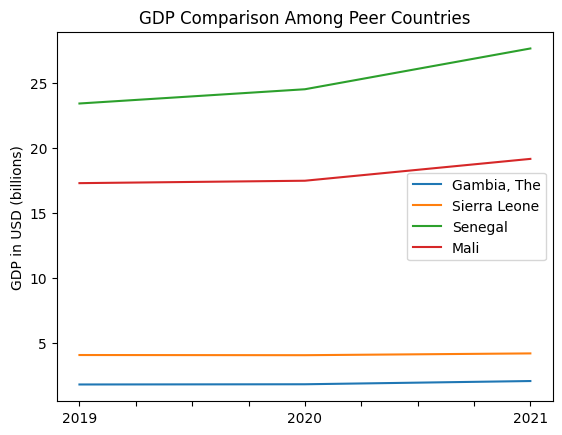

In [26]:
gdp_comparison_graph(comparable_countries)

In [27]:
# TO FIX - not CAGR in the file

def printgdps(cns):
   for cn in cns:
     print(cn)
     print(round(aagrate([x[1] for x in gdp_range_dict[cn]]),2))


gdp_percents = printgdps(comparable_countries)
gdp_percents

Gambia, The
4.82
Sierra Leone
1.02
Senegal
5.82
Mali
3.56


In [ ]:
# TO FIX - not CAGR in the file

gdp_percents = printgdps(comparable_countries) ## ADD THIS
#saves the output in a txt file
with open('comparable_countries_gdp.txt', 'w') as f:

    for cn in comparable_countries:
        f.write(cn + '\n')
        f.write(str(round(aagrate([x[1] for x in gdp_range_dict[cn]]),2)) + '\n')
        #write GDP %

Senegal
5.82
Nigeria
-0.52
Ethiopia
5.2
Burkina Faso
6.97


ECI Peer Comparison Graph

In [42]:
## UPDATED - MD
def eci_comparison_graph(cnames):
  fig, ax = plt.subplots()

  #cleanup country names
  for country_name in cnames:
    if country_name == 'Plurinational State of Bolivia':
      label = 'Bolivia'
    elif country_name == 'Norway, Svalbard and Jan Mayen':
      label = 'Norway'
    elif country_name == 'Russian Federation':
      label = 'Russia'
    elif country_name == 'France':
      country_name = 'France, Monaco'
      label = 'France'
    else:
      label = country_name

    x_values = [int(x[0]) for x in eci_19to21_dict[country_name]]
    y_values = [x[1] for x in eci_19to21_dict[country_name]]

    # Create the plot
    ax.plot(x_values, y_values, label = label)

    # Set the tick labels to custom values, '' added for consistent labeling
    ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])
    # print(eci_19to21_dict[country_name])

  plt.ylabel('ECI')
  plt.legend()
  plt.title('ECI Comparison Among Peer Countries')
  #saves figure as png
  plt.savefig('ECI Comparison for ' + country_name + '.png')
  plt.show()


<ipython-input-42-ebeb0e2fc138>:26: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])


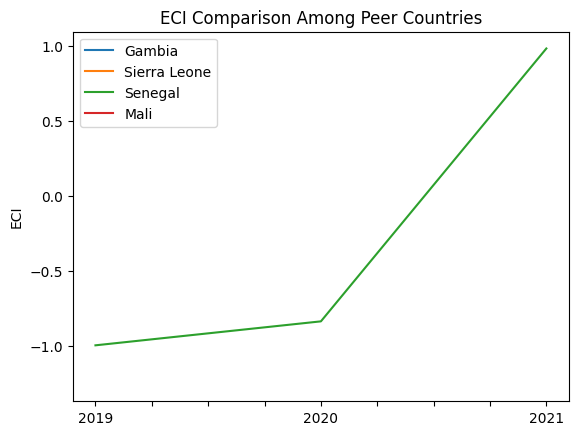

In [43]:
eci_comparison_graph(comparable_countries)

In [ ]:


# this is eci_change
#TO FIX - country names + more descriptive file?
#saves output as txt file


with open('comparable_countries_eci_19to21_dict.txt', 'w') as f:
    for country_name in comparable_countries:
        if country_name == 'France':
            country_name = 'France, Monaco'
        elif country_name == "Korea, Rep.":
            country_name = 'Republic of Korea'
        f.write(country_name + '\n')
        f.write(str(round((eci_19to21_dict[country_name][len(eci_19to21_dict[country_name])-1][1]-eci_19to21_dict[country_name][0][1])/abs(eci_19to21_dict[country_name][0][1]) * 100,2)) + '\n')




In [45]:
print(eci_19to21_dict)

defaultdict(<class 'list'>, {'Botswana': [(2019, -2.2319649564493194), (2020, -1.9498838287837046), (2021, 1.993549798702788)], 'Angola': [(2019, -2.078646357483305), (2020, -1.9282173017639663), (2021, 2.231673373922601)], 'United Arab Emirates': [(2019, -2.078646357483302), (2020, -1.928217301763967), (2021, 2.2316733739226016)], 'Azerbaijan': [(2019, -1.6545359138114564), (2020, -1.1887035815184788), (2021, 1.2195892852743209)], 'Burundi': [(2019, -1.5489227705430715), (2020, -1.1866653795502322), (2021, 1.1621321989241515)], 'Colombia': [(2019, -1.5489227705430715), (2020, -0.8416495964225394), (2021, 1.058293745453358)], 'Namibia': [(2019, -1.3591051651589163), (2020, -1.176680642903975)], 'Samoa': [(2019, -1.312460651235234), (2021, 1.4151255408686207)], 'Mali': [(2019, -1.255905303297797)], 'Zimbabwe': [(2019, -1.237740509724676), (2020, -1.1519939004896085), (2021, 1.0290290669653241)], 'Australia': [(2019, -1.2326650878329575), (2020, -0.9491207440346253), (2021, 1.12603724653

In [ ]:
## To FIX
def eci_change(cns):
  for country_name in cns:
    if country_name == 'France':
      country_name = 'France, Monaco'
    elif country_name == "Korea, Rep.":
      country_name = 'Republic of Korea'

    print(country_name)
    print(round((eci_19to21_dict[country_name][len(eci_19to21_dict[country_name])-1][1]-eci_19to21_dict[country_name][0][1])/abs(eci_19to21_dict[country_name][0][1]) * 100,2))

#ok to double print output here

eci_change(comparable_countries)

Senegal
199.02
Nigeria
147.83
Ethiopia
-6.74
Burkina Faso
0.0


In [ ]:

# TO FIX - need an actual ECI Value
[print(x)  for x in eci_19to21_dict[country_name]]

(2020, -0.8728523614652818)


[None]

GDP Growth and ECI Trend Graph

In [ ]:
## ## UPDATED - MD:
def gdp_and_eci_graph(country_name):
  if country_name=='Vietnam': #not sure if some other names should be changed too
    country_name='Viet Nam'
  elif country_name == 'France':
    country_name = 'France, Monaco'

  fig, ax1 = plt.subplots()

  ax1.set_ylabel('GDP in USD (billions)')
  x_values = [x[0] for x in gdp_range_dict[country_name]]
  y_values = [float(x[1])/(10**9) for x in gdp_range_dict[country_name]]
    # Create the plot
  ax1.plot(x_values, y_values, color = 'red', label='GDP')

  # Set the tick labels to custom values, '' added for consistent labeling
  ax1.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])
  ax1.legend(loc = 'upper left')

  ax2 = ax1.twinx()
  ax2.set_ylabel('ECI')
  ax2.plot(x_values,[x[1] for x in eci_19to21_dict[country_name]], color = 'blue', label='ECI')
  ax2.legend(loc = 'upper right')
  plt.title('GDP and ECI Trend for ' + country_name)
  plt.savefig('GDP and ECI Trend for ' + country_name + '.png')
  plt.show()

<ipython-input-37-d41fc0536764>:17: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax1.set_xticklabels(['', '2019', '', '', '', '2020', '', '',  '', '2021', ''])


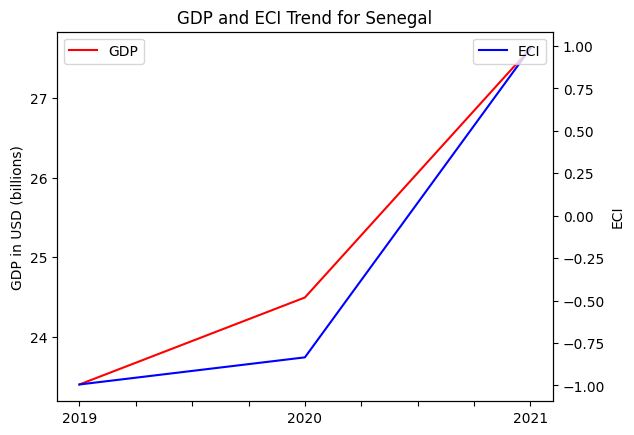

In [ ]:
gdp_and_eci_graph(main_country)

# Proximity, Distance, and RID

Proximity

In [ ]:
def compute_proximity(mcp,product_sum):
  proximity = []
  for i in range(0,len(mcp[0])):
    product_row = []
    for j in range(0,len(mcp[0])):
      temp_sum = 0
      for k in range(0,len(mcp)):
        try:
          temp_sum += mcp[k][i] * mcp[k][j]
        except:
          pass
      p0 = product_sum[i]
      p1 = product_sum[j]
      if p0 < p1:
        large = p1
      else:
        large = p0
      product_row.append(temp_sum/large)
    proximity.append(product_row)
  return proximity

Distance

In [ ]:
#compute distance
def compute_distance(mcp,proximity):
  distance = []
  for i in range(0,len(mcp)):
    product_row = []
    for j in range(0,len(mcp[0])):
      sum1 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum1 += mcp[i][k]*proximity[j][k]
          except:
            pass
      sum2 = 0
      for k in range(0,len(mcp[0])):
        if k != j:
          try:
            sum2 += proximity[j][k]
          except:
            pass
      product_row.append(1-sum1/sum2)
    distance.append(product_row)
  return distance

RID

In [ ]:
def compute_adi(df_middle,country_list,distance):
  raw_matrix = df_middle.to_numpy()
  matrix = [list(df_middle.columns)]
  for row in raw_matrix:
    if sum(row[1::]) > 0:
      matrix.append(list(row))

  country_list2,product_list2,mcp2,product_sum2,country_sum2 = compute_mcp(matrix)
  proximity2 = compute_proximity(mcp2,product_sum2)
  distance2 = compute_distance(mcp2,proximity2)

  adi = {}
  for i in range(len(country_list)):
    for j in range(len(country_list2)):
      if country_list[i] == country_list2[j]:
        adi[country_list[i]] = np.array(distance2[j]) - np.array(distance[i])
  return adi, country_list2,product_list2

In [ ]:
# 18 is equivalent to year 2021
proximity = compute_proximity(mcp,product_sum)
proximity_last_year = compute_proximity(mcp_last_year,product_sum_last_year)

distance = compute_distance(mcp,proximity)
adi, country_list2,product_list2  = compute_adi(df_middle,country_list,distance)

In [ ]:
#print(adi)

In [ ]:
# UPDATED
df_ = pd.DataFrame()
df_['Category'] = product_list_last_year
df_['RID'] = adi[main_country]
df_.sort_values(by="RID", inplace = True)

# Export the DataFrame to an Excel file
filename = main_country + '_RID.xlsx'
df_.to_excel(filename, index=True)
print('ADI results saved to', filename)

ADI results saved to Senegal_RID.xlsx


In [ ]:
#leading countries TO DO optional:

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year
country_list = sdv_leading_countries #change at the top
for count in country_list:
  df_comp[count + ' RID'] = adi[count]

df_comp.sort_values(by = country_list[0] + ' RID', inplace = True)
# Export the DataFrame to an Excel file
filename = 'sdv_leading_countries_RID1.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

RID results saved to sdv_leading_countries_RID1.xlsx


In [ ]:
#emerging countries TO DO optional:

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year

country_list = sdv_emerging_countries #change at the top
for count in country_list:
  df_comp[count + ' RID'] = adi[count]

df_comp.sort_values(by = country_list[0] + ' RID', inplace = True)
# Export the DataFrame to an Excel file
filename = 'sdv_emerging_countries_RID2.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

RID results saved to sdv_emerging_countries_RID2.xlsx


In [ ]:
# UPDATED - for multiple countries with the main country

df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year
country_list = sdv_comparable_countries  #TO DO - change in the header
for count in country_list:
  df_comp[count + ' RID'] = adi[count]
  print(count)
  print(eci_19to21_dict[count])

df_comp.sort_values(by = main_country + ' RID', inplace=True)
# Export the DataFrame to an Excel file
filename = 'more_countries_RID3.xlsx'
df_comp.to_excel(filename, index=True)
print('RID results saved to', filename)

Senegal
[(2019, -0.9947586270666169), (2020, -0.8349307570279886), (2021, 0.9849709847898797)]
Greece
[(2019, -0.22041012101379723), (2020, -0.13309105880044883), (2021, 0.2303579384876731)]
Poland
[(2019, 0.9509583514381877), (2020, 0.3843494286891375), (2021, -0.2936310146129229)]
Portugal
[(2019, 0.6295678745101799), (2020, 0.13243477930172193), (2021, -0.0452593366466747)]
France, Monaco
[(2019, 0.9597933674797456), (2020, 0.6935028761518204), (2021, -0.5667463341623193)]
RID results saved to more_countries_RID3.xlsx


In [ ]:
df_comp

,Category,Senegal RID,Greece RID,Poland RID,Portugal RID,"France, Monaco RID"
11,Machinery and Construction,-0.139723,-0.038720,-0.019723,-0.058638,0.020738
4,Chemicals,-0.136086,-0.036412,-0.014719,-0.064970,-0.011985
6,Raw Manufacturing,-0.122980,-0.028959,-0.003618,-0.084855,-0.023252
8,Clothing and Accessories,-0.120171,0.008191,0.045773,0.009998,0.010170
1,"Vegetables, Fruits and Plants",-0.118909,-0.011328,0.027068,-0.006802,0.017687
0,Animals and By-products,-0.115010,-0.019800,0.022730,-0.008091,0.011525
14,Daily Instruments,-0.108039,-0.042296,-0.020153,-0.008680,-0.017109
13,Weapons,-0.107312,-0.019627,0.012130,-0.052194,0.004409
12,Transportation,-0.103619,-0.044641,-0.041009,-0.152760,-0.005112
2,Food and Preparations,-0.091602,-0.016354,0.024521,-0.011646,0.011947


# Sequential Strategy

Opportunity Gain

In [ ]:
#compute opportunity gain
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        country_row.append(gain)
      #country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

Marginal Opportunity Gain

In [ ]:
#computes marginal opportunity gain
def compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix):
  marginal = []
  total_sum = np.sum(product_sum)
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      if mcp[i][j] == 1:
        country_row.append(0)
      else:
        export = matrix[i+1][j+1]
        country_export = country_sum[i]
        product_export = product_sum[j]
        export_increase = (product_export*country_export/total_sum)-export
        country_row.append(opportunity_gain[i][j]*export/export_increase)
    marginal.append(country_row)

  marginal = np.array(marginal)
  return marginal

In [ ]:
opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_last_year,proximity_last_year,pci_last_year)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)

#for i in range(len(country_list)):
#  print(country_list[i],opportunity_gain[i])

In [ ]:
# For computation of sequential strategies, refer to sequential strategy.py

In [ ]:
# For sensitivity analysis, refer to sensitivity.ipynb

In [ ]:
# For computation of SOI, soi.ipynb

# SDV & SIDS

In [ ]:
# returns a matrix of data read from a csv with the inputed filename
def read_country(filename):
    f = open(filename,'r', encoding='utf-8')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix

# takes a dictionary of scores as input and returns a list of items sorted in descending order based on their scores
def rank(score_dict):
    rank_list = []
    score_list = []
    for item in score_dict:
        score_list.append(score_dict[item])
    while score_list:
        maximum = max(score_list)
        for item in score_dict:
            if score_dict[item] == maximum:
                rank_list.append(item)
        score_list = [score for score in score_list if score!= maximum]
    return rank_list


def sdv_and_sids(country, year):
    wfile = "drive/My Drive/New_result_update/" + "sdv_and_sids" + country +  ".txt"
    print(wfile)
    #Read the raw matrix
    raw_matrix = read_country(f"{year}.csv")
    raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]
    raw_matrix[19][3] = raw_matrix[19][3]
    #compute mcp
    product_list = raw_matrix[0][1::]
    country_list = []
    for i in range(1,len(raw_matrix)):
        country_list.append(raw_matrix[i][0])

    country_sum = []
    for i in range(1,len(raw_matrix)):
        country_sum.append(np.sum(raw_matrix[i][1::]))

    product_sum = []
    for i in range(1,len(raw_matrix[0])):
        product = 0
        for j in range(1,len(raw_matrix)):
            product += raw_matrix[j][i]
        product_sum.append(product)
    total_sum = np.sum(product_sum)

    print(product_list)
    print(country_list)

    mcp = []

    for i in range (1,len(raw_matrix)):
        country_row = []
        for j in range(1,len(raw_matrix[i])):
            percentage = raw_matrix[i][j]/country_sum[i-1]
            total_percentage = product_sum[j-1]/total_sum
            if percentage > total_percentage:
                country_row.append(1)
            else:
                country_row.append(0)
        mcp.append(country_row)

    #compute mpp
    country_sum2 = []
    for i in range(0,len(mcp)):
        country_sum2.append(np.sum(mcp[i]))

    product_sum2 = []
    for i in range(0,len(mcp[0])):
        product = 0
        for j in range(0,len(mcp)):
            product += mcp[j][i]
        product_sum2.append(product)

    mpp = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                except:
                    pass
            product_row.append(temp_sum)
        mpp.append(product_row)

    #compute PCI
    mpp = np.array(mpp)

    e_vals, e_vecs = LA.eig(mpp)
    eigenvectors = e_vecs.tolist()
    eigen = []
    for eigenvector in eigenvectors:
        temp = []
        for col in eigenvector:
            temp.append(col.real)
        eigen.append(temp)

    vector = []
    for i in range(0,len(eigen)):
        vector.append(eigen[i][1])

    pci = []
    if vector[len(vector)-2] > 0:
        for item in vector:
            pci.append((item-np.mean(vector))/np.std(vector))
    else:
        for item in vector:
            pci.append((-item+np.mean(vector))/np.std(vector))

    #compute proximity
    proximity = []
    for i in range(0,len(mcp[0])):
        product_row = []
        for j in range(0,len(mcp[0])):
            temp_sum = 0
            for k in range(0,len(mcp)):
                try:
                    temp_sum += mcp[k][i] * mcp[k][j]
                except:
                    pass
            p0 = product_sum2[i]
            p1 = product_sum2[j]
            if p0 < p1:
                large = p1
            else:
                large = p0
            product_row.append(temp_sum/large)
        proximity.append(product_row)

    #compute actual distance
    distance = []
    for i in range(0,len(mcp)):
        product_row = []
        for j in range(0,len(mcp[0])):
            sum1 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum1 += (1-mcp[i][k])*proximity[j][k]
                except:
                    pass
            sum2 = 0
            for k in range(0,len(mcp[0])):
                try:
                    sum2 += proximity[j][k]
                except:
                    pass
            if mcp[i][j] == 1:
                product_row.append(0)
            else:
                product_row.append(sum1/sum2)
        distance.append(product_row)

    #compute opportunity gain
    opportunity_gain = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            gain = 0
            for k in range(0,len(mcp[0])):
                temp = 0
                for l in range(0,len(mcp[0])):
                    temp += proximity[l][k]
                gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
            gain = gain - (1-distance[i][j]) * pci[j]
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                country_row.append(gain)
        opportunity_gain.append(country_row)

    #compute marginal opportunity gain
    marginal = []
    for i in range(0,len(mcp)):
        country_row = []
        for j in range(0,len(mcp[0])):
            if mcp[i][j] == 1:
                country_row.append(0)
            else:
                export = raw_matrix[i+1][j+1]
                country_export = country_sum[i]
                product_export = product_sum[j]
                export_increase = (product_export*country_export/total_sum)-export
                country_row.append(opportunity_gain[i][j]*country_export/export_increase)
        marginal.append(country_row)


    #computing sequential strategy
    strategy = []

    for i in range(0,len(country_list)):
        if country in country_list[i]:
            country_index = i
    og = np.copy(opportunity_gain[country_index])
    sdv = dict(zip(product_list, og))
    sdv = sorted(sdv.items(), key=operator.itemgetter(1), reverse=True)
    sdv_colors = []
    for i in range(len(sdv)):
        if sdv[i][1]>0:
          sdv_colors.append(44)
        elif sdv[i][1]==0:
          sdv_colors.append(27)
        else:
          sdv_colors.append(1)
    print("Before Iteration: ")
    writer = open(wfile, 'w')
    writer.write("Before Iteration: ")
    for i in range(0,len(marginal[country_index])):
        write_str = product_list[i] + ": " + str(marginal[country_index][i]) +" \n"

        writer.write(write_str)
        print(product_list[i], ": ", marginal[country_index][i])

    writer.write(" \n")
    print(" ")

    temp = []
    temp.append("Before Iteration")
    posi = {}
    zero = []
    nega = {}
    colors = []
    color = [1]
    for i in range(0,len(marginal[country_index])):
        if marginal[country_index][i] > 0:
            posi[product_list[i]] = marginal[country_index][i]
        elif marginal[country_index][i] == 0:
            zero.append(product_list[i])
        else:
            nega[product_list[i]] = marginal[country_index][i]
    posi = rank(posi)
    nega = rank(nega)
    temp.extend(posi)
    color.extend([44 for i in range(len(posi))])
    temp.extend(zero)
    color.extend([27 for i in range(len(zero))])
    temp.extend(nega)
    color.extend([1 for i in range(len(nega))])
    strategy.append(temp)
    colors.append(color)

    ite_round = 0
    prev_industry = []

    while max(marginal[country_index]) > 0 and ite_round < 20:
        ite_round += 1

        value = max(marginal[country_index])
        for i in range(0,len(marginal[0])):
            if marginal[country_index][i] == value:
                industry_index = i
        industry = product_list[industry_index]
        prev_industry.append(industry_index)

        #calculate new export
        export = raw_matrix[country_index+1][industry_index+1]
        country_export = country_sum[country_index]
        product_export = product_sum[industry_index]
        required_export = product_export*country_export/total_sum
        export_increase = required_export-export

        print("increase ", industry, " in ", country, " by ", export_increase, " USD")
        write_str = "increase "+ industry + " in "+ country + " by "+ str(export_increase) + " USD" +" \n"

        writer.write(write_str)

        raw_matrix[country_index+1][industry_index+1] = required_export*1.3

        #calculate everything again
        country_sum = []
        for i in range(1,len(raw_matrix)):
            country_sum.append(np.sum(raw_matrix[i][1::]))

        product_sum = []
        for i in range(1,len(raw_matrix[0])):
            product = 0
            for j in range(1,len(raw_matrix)):
                product += raw_matrix[j][i]
            product_sum.append(product)
        total_sum = np.sum(product_sum)

        mcp = []

        for i in range (1,len(raw_matrix)):
            country_row = []
            for j in range(1,len(raw_matrix[i])):
                percentage = raw_matrix[i][j]/country_sum[i-1]
                total_percentage = product_sum[j-1]/total_sum
                if percentage > total_percentage:
                    country_row.append(1)
                else:
                    country_row.append(0)
            mcp.append(country_row)

        #compute mpp
        country_sum2 = []
        for i in range(0,len(mcp)):
            country_sum2.append(np.sum(mcp[i]))

        product_sum2 = []
        for i in range(0,len(mcp[0])):
            product = 0
            for j in range(0,len(mcp)):
                product += mcp[j][i]
            product_sum2.append(product)

        mpp = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += (mcp[k][i] * mcp[k][j]/(country_sum2[k]*product_sum2[i]))
                    except:
                        pass
                product_row.append(temp_sum)
            mpp.append(product_row)

        #compute PCI
        mpp = np.array(mpp)

        e_vals, e_vecs = LA.eig(mpp)
        eigenvectors = e_vecs.tolist()
        eigen = []
        for eigenvector in eigenvectors:
            temp = []
            for col in eigenvector:
                temp.append(col.real)
            eigen.append(temp)

        vector = []
        for i in range(0,len(eigen)):
            vector.append(eigen[i][1])

        pci = []
        if vector[len(vector)-2] > 0:
            for item in vector:
                pci.append((item-np.mean(vector))/np.std(vector))
        else:
            for item in vector:
                pci.append((-item+np.mean(vector))/np.std(vector))

        #compute proximity
        proximity = []
        for i in range(0,len(mcp[0])):
            product_row = []
            for j in range(0,len(mcp[0])):
                temp_sum = 0
                for k in range(0,len(mcp)):
                    try:
                        temp_sum += mcp[k][i] * mcp[k][j]
                    except:
                        pass
                p0 = product_sum2[i]
                p1 = product_sum2[j]
                if p0 < p1:
                    large = p1
                else:
                    large = p0
                product_row.append(temp_sum/large)
            proximity.append(product_row)

        #compute actual distance
        distance = []
        for i in range(0,len(mcp)):
            product_row = []
            for j in range(0,len(mcp[0])):
                sum1 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum1 += (1-mcp[i][k])*proximity[j][k]
                    except:
                        pass
                sum2 = 0
                for k in range(0,len(mcp[0])):
                    try:
                        sum2 += proximity[j][k]
                    except:
                        pass
                if mcp[i][j] == 1:
                    product_row.append(0)
                else:
                    product_row.append(sum1/sum2)
            distance.append(product_row)

        #compute opportunity gain
        opportunity_gain = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                gain = 0
                for k in range(0,len(mcp[0])):
                    temp = 0
                    for l in range(0,len(mcp[0])):
                        temp += proximity[l][k]
                    gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
                gain = gain - (1-distance[i][j]) * pci[j]
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    country_row.append(gain)
            opportunity_gain.append(country_row)

        #compute marginal opportunity gain
        marginal = []
        for i in range(0,len(mcp)):
            country_row = []
            for j in range(0,len(mcp[0])):
                if mcp[i][j] == 1:
                    country_row.append(0)
                else:
                    export = raw_matrix[i+1][j+1]
                    country_export = country_sum[i]
                    product_export = product_sum[j]
                    export_increase = (product_export*country_export/total_sum)-export
                    country_row.append(opportunity_gain[i][j]*country_export/export_increase)
            marginal.append(country_row)

        print("Iteration ", ite_round, ": ")
        write_str = "Iteration "+ str(ite_round)+ ": " + " \n"


        writer.write(write_str)
        for i in range(0,len(marginal[country_index])):
            write_str = product_list[i]+ ": "+ str(marginal[country_index][i])+ " \n"
            print(product_list[i], ": ", marginal[country_index][i])

            writer.write(write_str)
        print(" ")

        writer.write(" \n")

        temp = []
        string = "Iteration " + str(ite_round)
        temp.append(string)
        posi = {}
        zero = []
        nega = {}
        color = [1]
        for i in range(0,len(marginal[country_index])):
            if marginal[country_index][i] > 0:
                posi[product_list[i]] = marginal[country_index][i]
            elif marginal[country_index][i] == 0:
                zero.append(product_list[i])
            else:
                nega[product_list[i]] = marginal[country_index][i]
        posi = rank(posi)
        nega = rank(nega)
        temp.extend(posi)
        color.extend([44 for i in range(len(posi))])
        temp.extend(zero)
        color.extend([27 for i in range(len(zero))])
        temp.extend(nega)
        color.extend([1 for i in range(len(nega))])
        strategy.append(temp)
        colors.append(color)

    strategy = np.array(strategy)
    strategy = np.transpose(strategy)
    colors = np.array(colors)
    colors = np.transpose(colors)
    #print(f'color shape is {colors.shape}')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(strategy)):
        for j in range(len(strategy[0])):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = colors[i][j]
          sheet1.write(i,j,strategy[i][j], st)
    book.save(f'sequential strategy of {country}.xls')

    book = Workbook()
    sheet1 = book.add_sheet('Sheet 1')
    for i in range(0,len(sdv)):
          st = xlwt.easyxf('pattern: pattern solid;')
          st.pattern.pattern_fore_colour = sdv_colors[i]
          sheet1.write(i, 0, sdv[i][0], st)
    book.save(f'sequential vector of {country}.xls')
    write_str = country + " completed"

    writer.write(write_str)
    writer.close()
    print(f'{country} completed')


## UPDATED - MD:  from here only
# TO DO: update "comparable_countries" below if needed
def main():
    countries = comparable_countries
    for country in countries:
      if country == 'France':
        country = 'France, Monaco'

      sdv_and_sids(country, root_path+'2019-2021 cleaned/2021clean')

In [ ]:
##OLD - ending of the code above
'''
def main():
    countries = ['Viet Nam','Lao People\'s Dem. Rep.','Cambodia', 'Thailand']

    for country in countries:
        sdv_and_sids(country, root_path+'2013-2018 cleaned/2018clean')
        '''

"\ndef main():\n    countries = ['Viet Nam','Lao People's Dem. Rep.','Cambodia', 'Thailand']\n\n    for country in countries:\n        sdv_and_sids(country, root_path+'2013-2018 cleaned/2018clean')\n        "

In [ ]:
main()

drive/My Drive/New_result_update/sdv_and_sidsSenegal.txt
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
['China', 'Angola', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Plurinational State of Bolivia', 'Bosnia Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Canada', 'Cayman Islands', 'Chile', 'China, Hong Kong Special Administrative Region', 'China, Macao Special Administrative Region', 'Colombia', 'Comoros', 'Congo', 'Costa Rica', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic

<ipython-input-55-16db173cf7f4>:37: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]


Before Iteration: 
Animals and By-products :  0
Vegetables, Fruits and Plants :  0
Food and Preparations :  0
Energy Drilling and Mining :  0
Chemicals :  0
Chemical Manufacturing :  7.536380437331976
Raw Manufacturing :  6.130228294504966
Wood Products :  25.88217012039326
Clothing and Accessories :  20.761017728416622
Textile :  444.6562798405932
Metals :  11.143066094189606
Machinery and Construction :  98.4594776235997
Transportation :  1.9577284013521323
Weapons :  652.9049768040769
Daily Instruments :  5.725053546831133
Precious Stones	 :  0
High-complexity Products :  2.543600796865502
Services and Utilities :  13.854784012335296
 
increase  Weapons  in  Senegal  by  2734874.5851614205  USD
Iteration  1 : 
Animals and By-products :  0
Vegetables, Fruits and Plants :  0
Food and Preparations :  0
Energy Drilling and Mining :  0
Chemicals :  0
Chemical Manufacturing :  6.609111937355209
Raw Manufacturing :  5.669771750655236
Wood Products :  28.075385772020827
Clothing and Accesso

In [ ]:
if __name__ == "__main__":
    main()   #Optional: Change the countries and year above to have different results

drive/My Drive/New_result_update/sdv_and_sidsSenegal.txt
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
['China', 'Angola', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Plurinational State of Bolivia', 'Bosnia Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Canada', 'Cayman Islands', 'Chile', 'China, Hong Kong Special Administrative Region', 'China, Macao Special Administrative Region', 'Colombia', 'Comoros', 'Congo', 'Costa Rica', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic

<ipython-input-55-16db173cf7f4>:37: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]


Iteration  1 : 
Animals and By-products :  0
Vegetables, Fruits and Plants :  0
Food and Preparations :  0
Energy Drilling and Mining :  0
Chemicals :  0
Chemical Manufacturing :  6.609111937355209
Raw Manufacturing :  5.669771750655236
Wood Products :  28.075385772020827
Clothing and Accessories :  22.840618403771604
Textile :  464.68092927763814
Metals :  11.495154420821343
Machinery and Construction :  89.06657911083673
Transportation :  1.31725714310089
Weapons :  0
Daily Instruments :  4.4358629061912875
Precious Stones	 :  0
High-complexity Products :  1.9543208634329916
Services and Utilities :  11.738851352609883
 
increase  Textile  in  Senegal  by  3261913.6423269883  USD
Iteration  2 : 
Animals and By-products :  0
Vegetables, Fruits and Plants :  0
Food and Preparations :  0
Energy Drilling and Mining :  0
Chemicals :  0
Chemical Manufacturing :  6.659917269242025
Raw Manufacturing :  6.650919827067171
Wood Products :  33.952299191868924
Clothing and Accessories :  31.33367

In [ ]:
root_path

'drive/My Drive/ECI Research/4. Code Files/2022 Fall - Code/Data/'

In [ ]:
# UPDATED - SDV for multiple countries with main_country -tester
df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year
country_list_temp =  ["Italy"] #edited in the header
for count in country_list_temp:

  df_comp[count + ' SDV'] = sdv_and_sids(count, root_path+'2019-2021 cleaned/2021clean')
  print(count)
  print(eci_19to21_dict[count])

df_comp


drive/My Drive/New_result_update/sdv_and_sidsItaly.txt
['Animals and By-products', 'Vegetables, Fruits and Plants', 'Food and Preparations', 'Energy Drilling and Mining', 'Chemicals', 'Chemical Manufacturing', 'Raw Manufacturing', 'Wood Products', 'Clothing and Accessories', 'Textile', 'Metals', 'Machinery and Construction', 'Transportation', 'Weapons', 'Daily Instruments', 'Precious Stones\t', 'High-complexity Products', 'Services and Utilities']
['China', 'Angola', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Plurinational State of Bolivia', 'Bosnia Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Canada', 'Cayman Islands', 'Chile', 'China, Hong Kong Special Administrative Region', 'China, Macao Special Administrative Region', 'Colombia', 'Comoros', 'Congo', 'Costa Rica', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic',

<ipython-input-55-16db173cf7f4>:37: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  raw_matrix = [row for row in raw_matrix if np.all(row[1:]==np.zeros(len(row)-1)) == False]


Before Iteration: 
Animals and By-products :  6.417803567422472
Vegetables, Fruits and Plants :  32.944125057740216
Food and Preparations :  0
Energy Drilling and Mining :  0.6024921147756753
Chemicals :  -20.50658173831753
Chemical Manufacturing :  0
Raw Manufacturing :  0
Wood Products :  -13.517296663514061
Clothing and Accessories :  0
Textile :  0
Metals :  0
Machinery and Construction :  0
Transportation :  -3.7154647040352446
Weapons :  -8.94508179799644
Daily Instruments :  0
Precious Stones	 :  57.431721879373484
High-complexity Products :  0
Services and Utilities :  -50.04721403645682
 
increase  Precious Stones	  in  Italy  by  836743011.000824  USD
Iteration  1 : 
Animals and By-products :  32.75542487495419
Vegetables, Fruits and Plants :  112.85817411242493
Food and Preparations :  0
Energy Drilling and Mining :  4.119404528770971
Chemicals :  -20.327068731408737
Chemical Manufacturing :  0
Raw Manufacturing :  0
Wood Products :  32.45817255859535
Clothing and Accessorie

,Category,Italy SDV
0,Animals and By-products,None
1,"Vegetables, Fruits and Plants",None
2,Food and Preparations,None
3,Energy Drilling and Mining,None
4,Chemicals,None
5,Chemical Manufacturing,None
6,Raw Manufacturing,None
7,Wood Products,None
8,Clothing and Accessories,None
9,Textile,None


In [ ]:
# UPDATED - SDV for multiple countries with main_country
df_comp = pd.DataFrame()
df_comp['Category'] = product_list_last_year
country_list_temp =  sdv_comparable_countries #edited in the header
for count in country_list_temp:
  df_comp[count + ' SDV'] = sdv_and_sids(count, root_path+'2019-2021 cleaned/2021clean')
  print(count)
  print(eci_19to21_dict[count])

df_comp

# SOI

In [ ]:
# takes a filename argument as input and reads data from a CSV file with the specified filename and stores (and returns) it in a matrix.
def read_it(filename):
    f = open(filename,'r', encoding='cp1252')
    reader = csv.reader(f)
    raw_matrix = []
    for row in reader:
        temp = []
        for i in range(0,len(row)):
            try:
                temp.append(float(row[i]))
            except ValueError:
                #print(row[i])
                temp.append(row[i])
        raw_matrix.append(temp)
    f.close()
    return raw_matrix

In [ ]:
zzz+=1
#reads in adi, two county lists and their respective product lists,and opportunity gain: a list of lists that store the opportunity gain for each country and product combination
#outputs a dictionary SOI that contains the SOI values of each country that is in common with country_list and country_list2
def compute_soi_adi(adi, country_list, product_list, country_list2, product_list2, opportunity_gain):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    plt.scatter(independent, dependent)
                    plt.show()
                    print(model.cov_HC0)
                    print(country_list[i], "!!!")
                    print(country_list2[j], "???")
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
 #TO FIX PATH
    matrix = open(root_path+'structual optimality index adi ("+str(zzz)+ ").csv','w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in range(0,len(soi)):
       temp = [common[i],soi[common[i]]]
       writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
# compute the SOI for a list of countries and products based on their opportunity gain.
def compute_soi_oppgain(country_list, product_list,country_list2, product_list2, opportunity_gain, opportunity_gain2):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")

    common = []
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    independent=[]
                    dependent=[]
                    for item in opportunity_gain2[j]:
                        #dependent.append([item])
                        dependent.append(item)
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    # reg = LinearRegression()
                    # reg.fit(independent, dependent)
                    # r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I': independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    common.append(country_list[i])
                    soi[country_list[i]] =r_2
 #TO FIX PATH
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
#he function calculates the SOI for each country based on its relationship between
# changes in export values (exp_change) and opportunity gain (opportunity_gain)
def compute_soi_exp(country_list, product_list,country_list2, product_list2, opportunity_gain, exp_change):
    soi = {}
    if len(product_list) == len(product_list2):
        print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = []
                    independent = []
                    for item in opportunity_gain[i]:
                        #independent.append([item])
                        independent.append(item)
                    #print(opportunity_gain2[i])
                    for item in exp_change.loc[country_list[i],:]:
                        #dependent.append([item])
                        dependent.append(item)
                    #reg = LinearRegression()
                    #reg.fit(independent, dependent)
                    #r_2 = reg.score(independent, dependent)
                    dfs=  pd.DataFrame({'I':independent, 'D': dependent})
                    model = smf.ols(formula='D ~ I', data=dfs).fit()
                    r_2 = model.rsquared_adj
                    soi[country_list[i]] = r_2
  #TO FIX PATH
    matrix = open(root_path+"structual optimality index oppgain.csv",'w',newline='')
    writer = csv.writer(matrix)
    col_name = ["Country","SOI"]
    writer.writerow(col_name)
    for i in soi.keys():
        temp = [i,soi[i]]
        writer.writerow(temp)
    matrix.close()
    return soi

In [ ]:
# TO FIX years
# Issue with SOI in here: common2, independent, and dependent are all empty
# so model = smf.ols(formula='GDP ~ SOI', data=dfs).fit() throws a ValueError

def compute_regress(soi, gdp_raw, country_list, country_list2):
    #comprehensive regression
    common=np.intersect1d(country_list, country_list2)
    independent = []
    dependent = []
    name = []
    common2= []
    growth={}




    for i in common:
         country_exists = False

      #old
        #if i in gdp_raw.index.values and gdp_raw['2013'][i] != 0:
            #pct_change=(float(gdp_raw['2018'][i])-float(gdp_raw['2013'][i]))/float(gdp_raw['2013'][i])
         for e in range(0, len(gdp_raw["Country Name"])):

            if gdp_raw["Country Name"][e] == i:
              country_exists = True
              #print(country_exists)


         if country_exists:
            for z in range(0, len(gdp_raw["Country Name"])):
              if gdp_raw["Country Name"][z] == i:
                inde = z
            #print(inde)

            if gdp_raw['2019'][inde] != 0:

              pct_change=(float(gdp_raw['2021'][inde])-float(gdp_raw['2019'][inde]))/float(gdp_raw['2019'][inde])
              dependent.append(pct_change)
              independent.append(soi[i])
              growth[i]=pct_change
              common2.append(i)
    #print("Other lists")
    #print(len(common2))
    #print(len(dependent))
    #print(len(independent))
    # plt.scatter(independent,dependent)
    # plt.title('SOI v GDP Growth')
    # plt.xlabel('SOI')
    # plt.ylabel('% Change in GDP')
    # plt.show()

    # print(np.setdiff1d(common,common2))
    # print()
    # print(common)
    # print()
    # print(common2)

    dfs=  pd.DataFrame({'Country': common2,'GDP':dependent, 'SOI': independent})
    #dfs.set_index('Country', inplace=True)

    model = smf.ols(formula='GDP ~ SOI', data=dfs).fit()


    fig = px.scatter(dfs, x="SOI", y="GDP",  text='Country', trendline="ols")
    fig.update_layout(
#    yaxis_title="% Growth in GDP 2019-2021",
    xaxis_title="SOI",
    height=600,
    width=900,
    title_x=.5,
    font=dict(
        family="Times New Roman",
        size=15
        ) )
    #fig.update_traces(textposition='top center')
    fig2 = plt.figure(figsize=(12,8))
    fig2 = sm.graphics.plot_regress_exog(model,'SOI', fig=fig2)
    fig3, ax = plt.subplots(figsize=(12,8))
    fig3 = sm.graphics.influence_plot(model, ax=ax, criterion='Cooks')
    fig_name = "Regression of GDP over SOI.png"
    #fig.savefig(fig_name)
    #pio.write_image(fig, fig_name)
    fig.write_image(fig_name, engine="kaleido")
    fig.show()
    return model, growth

In [ ]:
# computes opportunity gain
def compute_opportunity_gain(mcp,proximity,pci):
  opportunity_gain = []
  for i in range(0,len(mcp)):
    country_row = []
    for j in range(0,len(mcp[0])):
      gain = 0
      for k in range(0,len(mcp[0])):
        temp = 0
        for l in range(0,len(mcp[0])):
          temp += proximity[l][k]
        gain += (proximity[j][k]/temp)*(1-mcp[i][k])*pci[k]
      gain = gain - (1-distance[i][j]) * pci[j]
      country_row.append(gain)
    opportunity_gain.append(country_row)

  opportunity_gain = np.array(opportunity_gain)
  return opportunity_gain

opportunity_gain = compute_opportunity_gain(mcp,proximity,pci)
opportunity_gain_18 = compute_opportunity_gain(mcp_last_year,proximity_last_year,pci_last_year)

marginal_opportunity_gain = compute_marginal_opportunity_gain(mcp,opportunity_gain,country_sum,product_sum,matrix)


In [ ]:
# Creates a scatter plot of the opportunity_gain and the adi for a specific country

def soi_plotter(country, adi, country_list, product_list,country_list2, product_list2, opportunity_gain):
    if len(product_list) == len(product_list2):
            print("categorization verified")
    for i in range(0,len(country_list)):
        if country_list[i] in country_list2 and country_list[i]==country:
            for j in range(0,len(country_list2)):
                if country_list[i] == country_list2[j]:
                    dependent = adi[country_list[i]]
                    independent = []
                    for item in opportunity_gain[i]:
                        independent.append(item)
                    # print(independent)
                    # print(dependent)
                    # print(product_list)
                    # Create figure with secondary y-axis
                    fig = make_subplots(specs=[[{"secondary_y": True}]])

                    # Add traces
                    fig.add_trace(
                        go.Scatter(x=product_list, y=independent, name="Opportunity Gain"),
                        secondary_y=False,
                    )

                    fig.add_trace(
                        go.Scatter(x=product_list, y=dependent, name="RID"),
                        secondary_y=True,
                    )

                    # Add figure title
                    fig.update_layout(
                        title_text="SOI of "+country
                    )
                    fig.update_layout(
                        height=600,
                        width=1500,
                        title_x=.5,
                        font=dict(
                            family="Times New Roman",
                            size=15
                            ) )
                    # Set x-axis title
                    fig.update_xaxes(title_text="Product Category")

                    # Set y-axes titles
                    fig.update_yaxes(title_text="RID", secondary_y=False)
                    fig.update_yaxes(title_text="Opportunity Gain", secondary_y=True)

                    correlation_matrix = np.corrcoef(dependent, independent)
                    correlation_xy = correlation_matrix[0,1]
                    r_squared = correlation_xy**2
                    print("ASDFASDFASDFSADFASDFASDFASDF R^2: ", r_squared, "ASDFASDFASDFASDF)\n\n\n") # TO FIX
                    figure_name = "SOI of "+ country + ".png"
                    #fig.savefig(figure_name)
                    #pio.write_image(fig, figure_name)
                    fig.write_image(figure_name, engine="kaleido")
                    fig.show()




###SOI w/ ADI

categorization verified


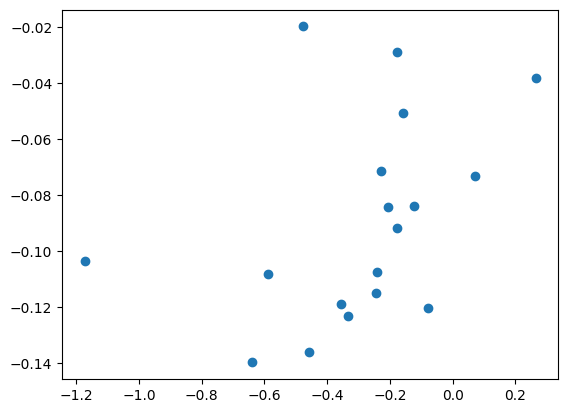

[[7.83000358e-05 1.02825783e-04]
 [1.02825783e-04 4.74888622e-04]]
Senegal !!!
Senegal ???


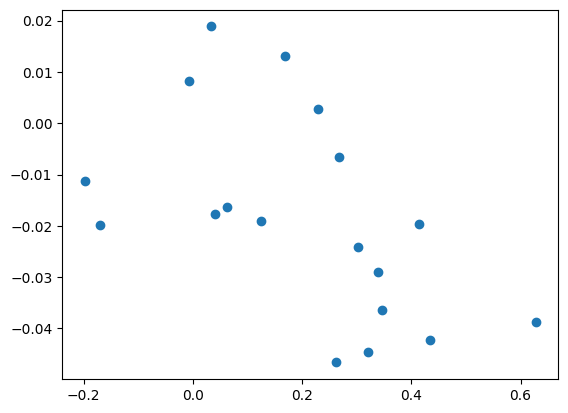

[[ 3.12817404e-05 -6.45537709e-05]
 [-6.45537709e-05  2.34115268e-04]]
Greece !!!
Greece ???


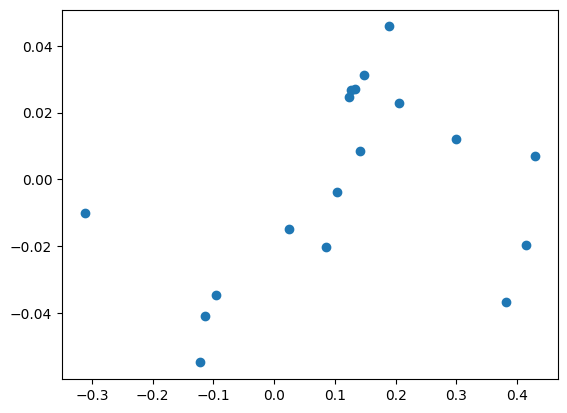

[[ 4.71978722e-05 -9.98305157e-05]
 [-9.98305157e-05  1.09044717e-03]]
Poland !!!
Poland ???


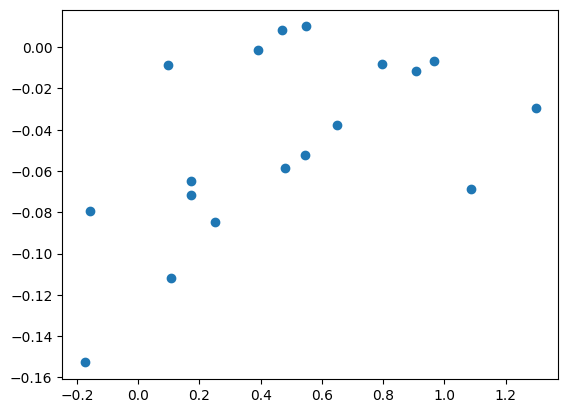

[[ 0.00024433 -0.00030858]
 [-0.00030858  0.00055036]]
Portugal !!!
Portugal ???


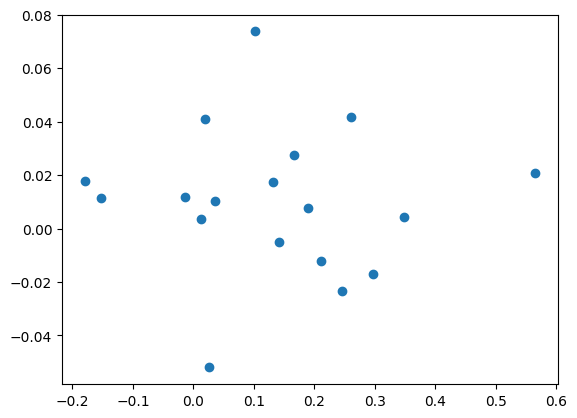

[[ 5.42201435e-05 -8.56373380e-05]
 [-8.56373380e-05  5.01867956e-04]]
France, Monaco !!!
France, Monaco ???
['Senegal', 'Greece', 'Poland', 'Portugal', 'France, Monaco']
155
[('France, Monaco', -0.06079558950607944), ('Poland', 0.05736941883169344), ('Senegal', 0.09513296147235517), ('Greece', 0.23499453620052935), ('Portugal', 0.24052553399033927)]
271


/usr/local/lib/python3.10/dist-packages/statsmodels/stats/stattools.py:74: ValueWarning:

omni_normtest is not valid with less than 8 observations; 4 samples were given.



<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    GDP   R-squared:                       0.772
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                     6.760
Date:                Fri, 17 Nov 2023   Prob (F-statistic):              0.122
Time:                        18:29:44   Log-Likelihood:                 8.7568
No. Observations:                   4   AIC:                            -13.51
Df Residuals:                       2   BIC:                            -14.74
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1967      0.041      4.745      0.042       0.018       0.375
SOI           -0.6086      0.234     -2.600      0.122      -1.616       0.399
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   1.467
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.305
Skew:                           0.450   Prob(JB):                        0.858
Kurtosis:                       1.990   Cond. No.                         12.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

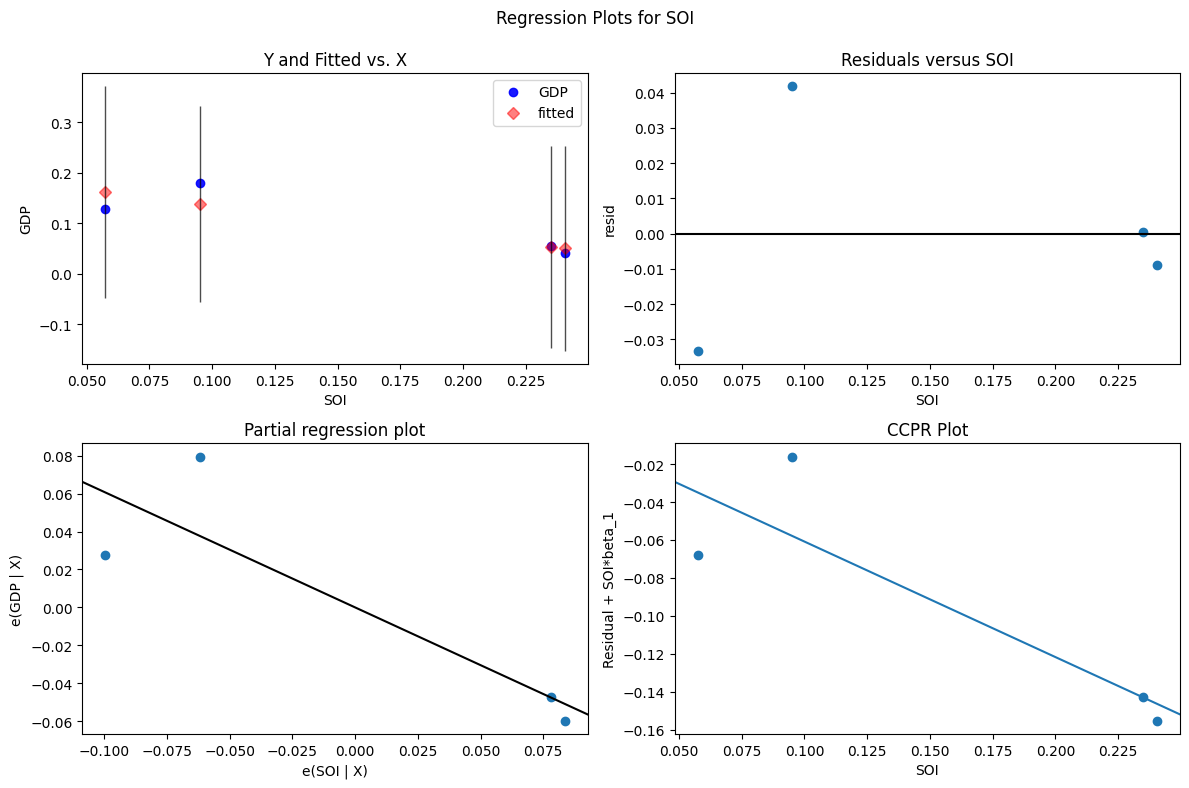

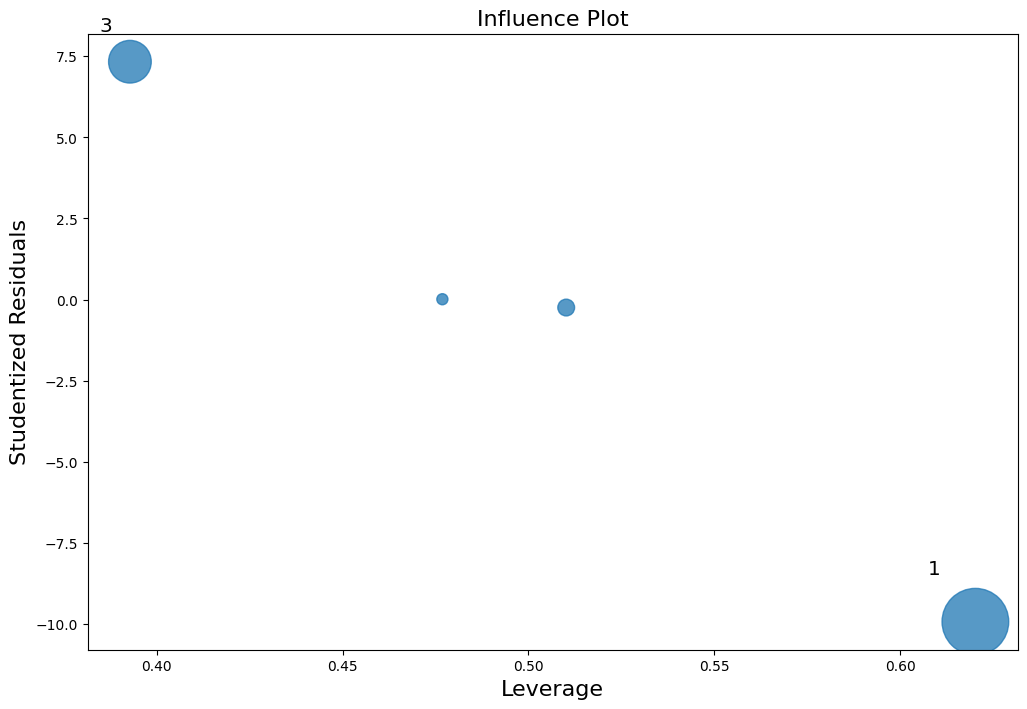

In [ ]:

soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))
gdp_raw=pd.read_csv(root_path+'GDP4.csv', index_col=0).fillna(0)
print(country_list)
print(len(country_list2))
print(soi_adi_list)
print(len(gdp_raw))
reg, growth = compute_regress(soi_adi, gdp_raw, country_list, country_list2)

reg.summary()

In [ ]:
soi_adi

{'Senegal': 0.09513296147235517,
 'Greece': 0.23499453620052935,
 'Poland': 0.05736941883169344,
 'Portugal': 0.24052553399033927,
 'France, Monaco': -0.06079558950607944}

categorization verified


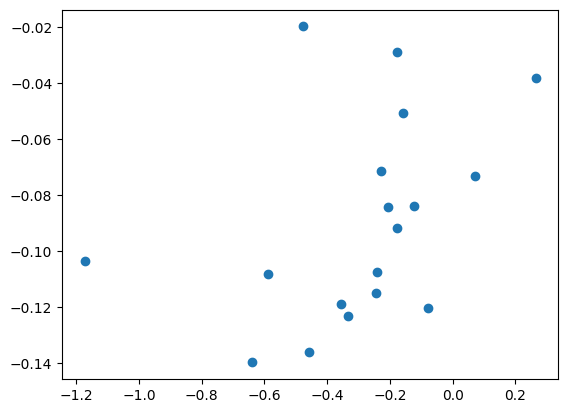

[[7.83000358e-05 1.02825783e-04]
 [1.02825783e-04 4.74888622e-04]]
Senegal !!!
Senegal ???


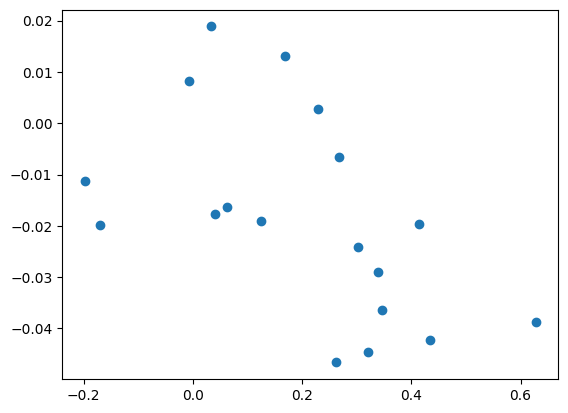

[[ 3.12817404e-05 -6.45537709e-05]
 [-6.45537709e-05  2.34115268e-04]]
Greece !!!
Greece ???


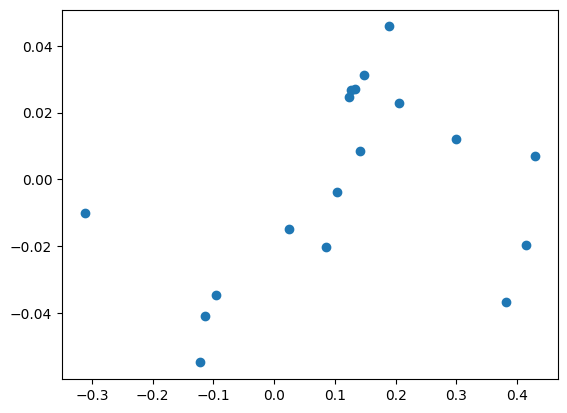

[[ 4.71978722e-05 -9.98305157e-05]
 [-9.98305157e-05  1.09044717e-03]]
Poland !!!
Poland ???


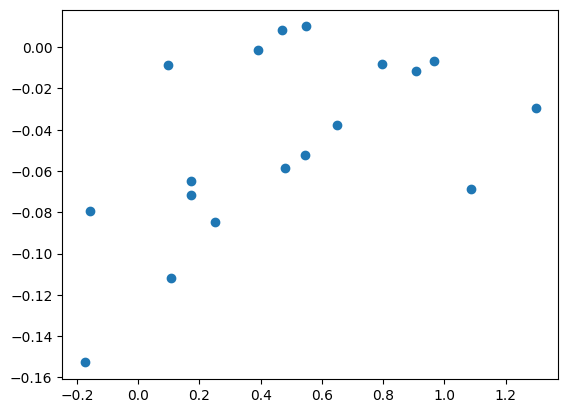

[[ 0.00024433 -0.00030858]
 [-0.00030858  0.00055036]]
Portugal !!!
Portugal ???


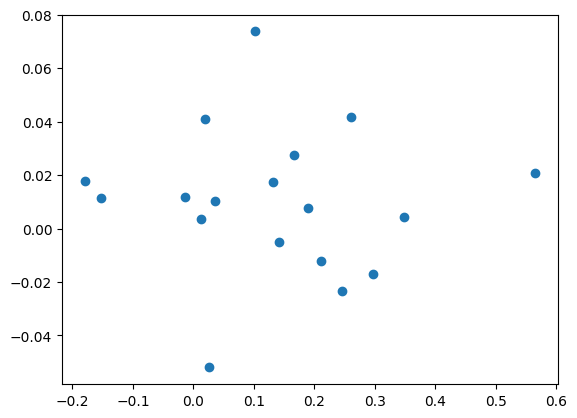

[[ 5.42201435e-05 -8.56373380e-05]
 [-8.56373380e-05  5.01867956e-04]]
France, Monaco !!!
France, Monaco ???


/usr/local/lib/python3.10/dist-packages/statsmodels/stats/stattools.py:74: ValueWarning:

omni_normtest is not valid with less than 8 observations; 4 samples were given.



<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    GDP   R-squared:                       0.772
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                     6.760
Date:                Fri, 17 Nov 2023   Prob (F-statistic):              0.122
Time:                        18:29:48   Log-Likelihood:                 8.7568
No. Observations:                   4   AIC:                            -13.51
Df Residuals:                       2   BIC:                            -14.74
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1967      0.041      4.745      0.042       0.018       0.375
SOI           -0.6086      0.234     -2.600      0.122      -1.616       0.399
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   1.467
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.305
Skew:                           0.450   Prob(JB):                        0.858
Kurtosis:                       1.990   Cond. No.                         12.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
soi_adi= compute_soi_adi(adi, country_list, product_list,country_list2, product_list2, opportunity_gain)
soi_adi_list = sorted(soi_adi.items(), key=operator.itemgetter(1))

#UPDATED - GDP4 needed other reworks

gdp_raw = df7.fillna(0)

#reg, growth = compute_regress(soi_adi, gdp_raw, country_list, country_list2)

# print(len(country_list))
# print(len(country_list2))
# print(len(soi_adi_list))
reg.summary()

In [ ]:
c= main_country
sorted_x = sorted(soi_adi.items(), key=lambda kv: kv[1], reverse=True)
for i in range(len(sorted_x)):
  print(i, "  ", sorted_x[i])
soi_plotter(c, adi, country_list, product_list, country_list2, product_list2, opportunity_gain)
print('SOI', soi_adi[c],'Growth', growth[c])
for i in growth.keys():
 if i=='Viet Nam':
  i='Vietnam'
  print(i, "\t", growth[i])

0    ('Portugal', 0.24052553399033927)
1    ('Greece', 0.23499453620052935)
2    ('Senegal', 0.09513296147235517)
3    ('Poland', 0.05736941883169344)
4    ('France, Monaco', -0.06079558950607944)
categorization verified
ASDFASDFASDFSADFASDFASDFASDF R^2:  0.14836043432692247 ASDFASDFASDFASDF)





SOI 0.09513296147235517 Growth 0.18063212064117193


SOI w/ Opportunity Gain

categorization verified
[('France, Monaco', -0.0605499514136143), ('Greece', 0.31256723552393395), ('Poland', 0.38255242261164524), ('Portugal', 0.8708427031608926), ('Senegal', 0.4162169562641369)]


/usr/local/lib/python3.10/dist-packages/statsmodels/stats/stattools.py:74: ValueWarning:

omni_normtest is not valid with less than 8 observations; 4 samples were given.



                            OLS Regression Results                            
Dep. Variable:                    GDP   R-squared:                       0.218
Model:                            OLS   Adj. R-squared:                 -0.174
Method:                 Least Squares   F-statistic:                    0.5560
Date:                Fri, 17 Nov 2023   Prob (F-statistic):              0.534
Time:                        18:29:50   Log-Likelihood:                 6.2932
No. Observations:                   4   AIC:                            -8.586
Df Residuals:                       2   BIC:                            -9.814
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.1607      0.087      1.838      0.2

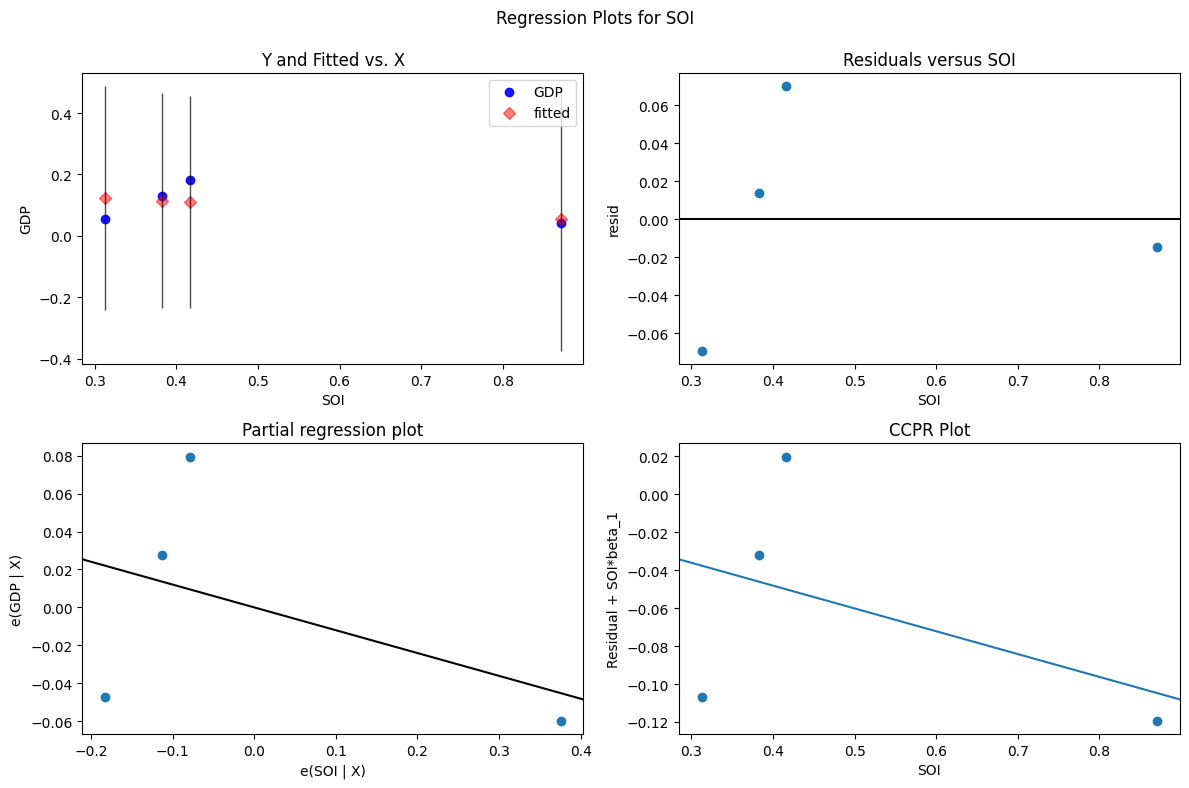

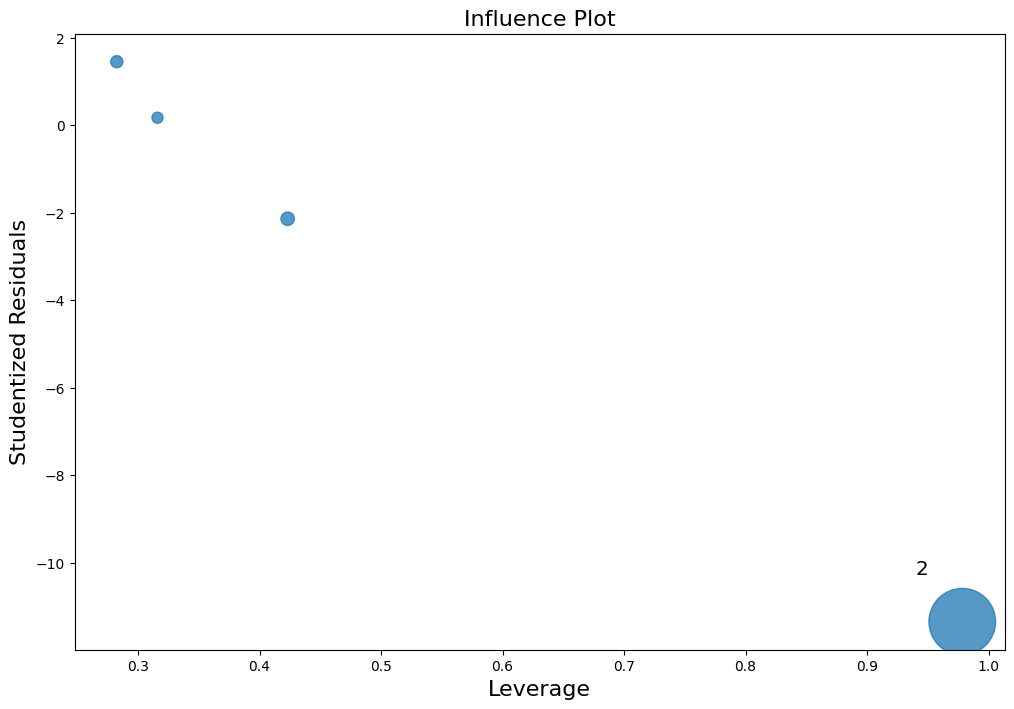

In [ ]:
soi_oppg= compute_soi_oppgain(country_list, product_list,country_list_last_year, product_list_last_year, opportunity_gain, opportunity_gain_18)
print(sorted(soi_oppg.items(), key=operator.itemgetter(0)))
#print(np.intersect1d(country_list,country_list_last_year))
reg_opp= compute_regress(soi_oppg, gdp_raw, country_list, country_list_last_year)
print(reg_opp[0].summary())

#reg_opp.summary()

###Greedy Algorithm - DON'T RUN?

In [ ]:


root_path = 'drive/My Drive/ECI Research/Fall 2022/Data/'

# Read input
#uploaded = files.upload()
#df_end = pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv')
#df_end_cl= pd.read_csv(root_path+'2019-2021 cleaned/2021clean.csv', index_col=0)

In [ ]:
## TO DO: Update the path
# inputs are country, year, perecentage, num_part
# outputs a dictionary of products and their export values and the maximum eci
def greedy(country, year, percentage, num_part):
  #new:
    #df = pd.read_csv(root_path + '2019-2021 cleaned/' + f'{year}clean.csv')
    wfile_name = country + str(year) + str(percentage) + str(num_part) + ".txt"
    wfile_path = "drive/My Drive/New_result_update/" + wfile_name
    print(wfile_name)
    print(wfile_path)
    df = pd.read_csv(root_path + '2019-2021 cleaned/2021clean.csv')
    raw_matrix = df.to_numpy()
    matrix = [list(df.columns)]

    for row in raw_matrix:
      if np.min(row[1::]) > 0:
        matrix.append(list(row))

    print(len(raw_matrix))
    product_list = matrix[0][1::]
    print(product_list)
    country_list = []
    for i in range(1,len(matrix)):
        country_list.append(matrix[i][0])
        if country in matrix[i][0]:
           country_index = i
           #print(country_index)
           total_export = np.sum(matrix[i][1::])

    budget = (percentage/100) * total_export
    print(f'Original total export is {total_export}, budget is {budget}')
    mcp = compute_mcp(matrix)[2]
    mcc = compute_mcc(mcp)
    last_eci = compute_eci(mcc)[country_index-1]
    print(f'ECI this year is {last_eci}')
    each_amount = budget/num_part
    original_vector = np.copy(matrix[country_index][1::])

    total = 0
    while total < budget:
        eci = []
        print(f'Progress: {round(total/budget, 2)}')
        for i in tqdm(range(1, len(matrix[0]))):
            matrix[country_index][i] += each_amount
            mcp = compute_mcp(matrix)[2]
            mcc = compute_mcc(mcp)
            eci.append(compute_eci(mcc)[country_index - 1])
            matrix[country_index][i] -= each_amount
        if  eci.count(max(eci)) != 1:
            #print('path 2')
            multiple = 2
            total_temp = total
            temp_each = multiple*each_amount
            while max(eci)<=last_eci and total_temp < budget:
                temp_each = multiple*each_amount
                print(f'Multiple = {multiple}, Raise each amount to {temp_each}')
                eci = []
                for i in tqdm(range(1, len(matrix[0]))):
                    matrix[country_index][i] += temp_each
                    mcp = compute_mcp(matrix)[2]
                    mcc = compute_mcc(mcp)
                    eci.append(compute_eci(mcc)[country_index - 1])
                    matrix[country_index][i] -= temp_each
                multiple += 1
                total_temp = total + temp_each
            if max(eci)<=last_eci and total_temp == budget:
               print('ECI does not change any more, add to the most adjacent ')
               export_increase = []
               mcp, product_sum, country_sum = compute_mcp(matrix)[2:]
               total_sum = np.sum(product_sum)
               for j in range(0,len(mcp[0])):
                  if mcp[country_index-1][j] == 1:
                      export_increase.append(0)
                  else:
                      export = raw_matrix[country_index][j+1]
                      country_export = country_sum[country_index-1]
                      product_export = product_sum[j]
                      export_increase.append((product_export*country_export/total_sum)-export)
               country_dist = np.array(export_increase)
               min_distance = np.where(country_dist > 0, country_dist, np.inf).argmin()
               matrix[country_index][min_distance + 1] += temp_each
            else:
               matrix[country_index][np.argmax(eci) + 1] += temp_each
               print(eci)
               print(f'After increasing, largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
               print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            total = total_temp
            last_eci = max(eci)
        else:
            #print('path 3')
            largest_component = np.argmax(eci) + 1
            print(eci)
            print(f'largest argument is {np.argmax(eci) + 1}, product is {product_list[np.argmax(eci)]}')
            print(f'last_eci is {last_eci}, this_eci is {max(eci)}')
            last_eci = max(eci)
            matrix[country_index][np.argmax(eci) + 1] += each_amount
            total += each_amount
    optimal_vector = np.array(matrix[country_index][1::]) - original_vector
    max_eci = last_eci
    with open(wfile_path, 'w') as writer:
      writer.write(str(dict(zip(product_list, optimal_vector))))
      writer.write(", "+ str(max_eci))
    return dict(zip(product_list,optimal_vector)), max_eci

##### Greedy Code

In [ ]:
## 1
## this one takes some time to run
## where greedy(country, year, percentage, num_part)
## TO DO: RUN code for 5%
# CHECK THE YEAR
# greedy(main_country, 2021, 5, 12)
#greedy(main_country, 2021, 10, 12)
# greedy(main_country, 2021, 15, 12)
#greedy(main_country, 2021, 20, 12)

# End